In [66]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

Here is important that we use the same half width window. The chosen one was 12s.

In [67]:
RANDOM_STATE = 42
METRIC = 'euclidean'
PERPLEXITY = 350

In [68]:
df_ont15_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont15_2022.parquet")
df_ont15_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont15_2023.parquet")
df_ont15_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont15_2024.parquet")
df_ont15_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont15_2025.parquet")

df_ont20_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont20_2022.parquet")
df_ont20_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont20_2023.parquet")
df_ont20_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont20_2024.parquet")
df_ont20_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont20_2025.parquet")

df_ont25_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont25_2022.parquet")
df_ont25_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont25_2023.parquet")
df_ont25_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont25_2024.parquet")
df_ont25_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont25_2025.parquet")

In [69]:
print(f"Number of triggers 2022: ont15={df_ont15_2022.shape[0]}, ont20={df_ont20_2022.shape[0]}, ont25={df_ont25_2022.shape[0]}")
print(f"Number of triggers 2023: ont15={df_ont15_2023.shape[0]}, ont20={df_ont20_2023.shape[0]}, ont25={df_ont25_2023.shape[0]}")
print(f"Number of triggers 2024: ont15={df_ont15_2024.shape[0]}, ont20={df_ont20_2024.shape[0]}, ont25={df_ont25_2024.shape[0]}")
print(f"Number of triggers 2025: ont15={df_ont15_2025.shape[0]}, ont20={df_ont20_2025.shape[0]}, ont25={df_ont25_2025.shape[0]}")

Number of triggers 2022: ont15=49599, ont20=30941, ont25=21251
Number of triggers 2023: ont15=35984, ont20=22485, ont25=15582
Number of triggers 2024: ont15=40872, ont20=25305, ont25=17356
Number of triggers 2025: ont15=20145, ont20=15064, ont25=10193


We will compare ont=15, ont=20 and ont=25 for the same year

2022 ont=15

In [70]:
df = df_ont15_2022.copy()

feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")
print(f"X.shape = {X.shape}")
X_max = X.max(axis=1, keepdims=True)

Number of features: 1230
X.shape = (49599, 1230)


In [71]:
X_norm = X / X_max

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (49599, 1230)


In [72]:
tsne = TSNE(n_components=2,perplexity=PERPLEXITY,early_exaggeration=14,init="pca",learning_rate="auto",random_state=RANDOM_STATE, metric=METRIC)
X_tsne = tsne.fit_transform(X_scaled)

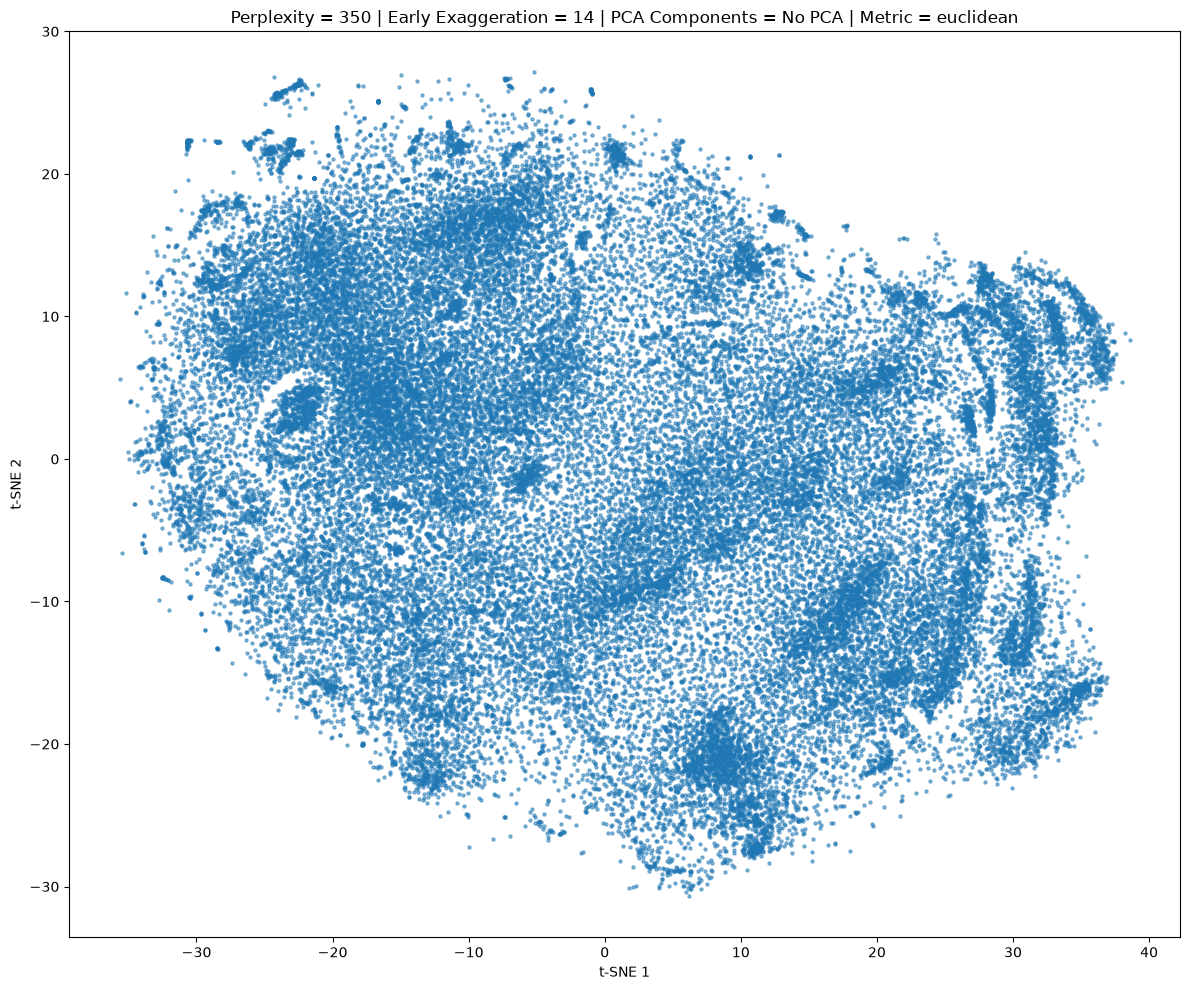

In [73]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"Perplexity = {PERPLEXITY} | Early Exaggeration = 14 | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

2022 ont=20

In [74]:
df = df_ont20_2022.copy()

feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")
print(f"X.shape = {X.shape}")
X_max = X.max(axis=1, keepdims=True)

Number of features: 1230
X.shape = (30941, 1230)


In [75]:
X_norm = X / X_max

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (30941, 1230)


In [76]:
tsne = TSNE(n_components=2,perplexity=PERPLEXITY,early_exaggeration=14,init="pca",learning_rate="auto",random_state=RANDOM_STATE, metric=METRIC)
X_tsne = tsne.fit_transform(X_scaled)

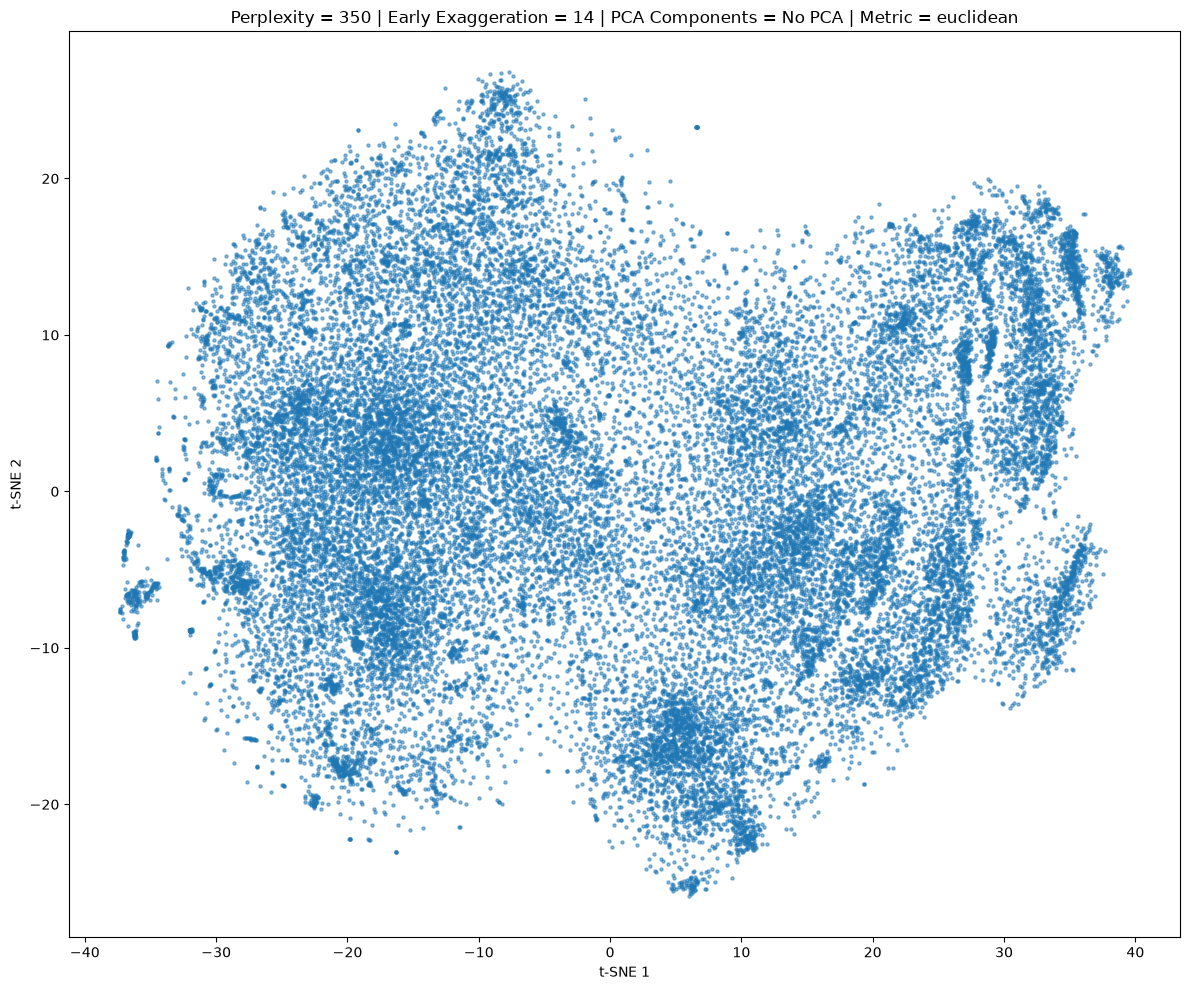

In [77]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"Perplexity = {PERPLEXITY} | Early Exaggeration = 14 | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

2022 ont=25

In [78]:
df = df_ont25_2022.copy()

feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")
print(f"X.shape = {X.shape}")
X_max = X.max(axis=1, keepdims=True)

Number of features: 1230
X.shape = (21251, 1230)


In [79]:
X_norm = X / X_max

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (21251, 1230)


In [80]:
tsne = TSNE(n_components=2,perplexity=PERPLEXITY,early_exaggeration=14,init="pca",learning_rate="auto",random_state=RANDOM_STATE, metric=METRIC)
X_tsne = tsne.fit_transform(X_scaled)

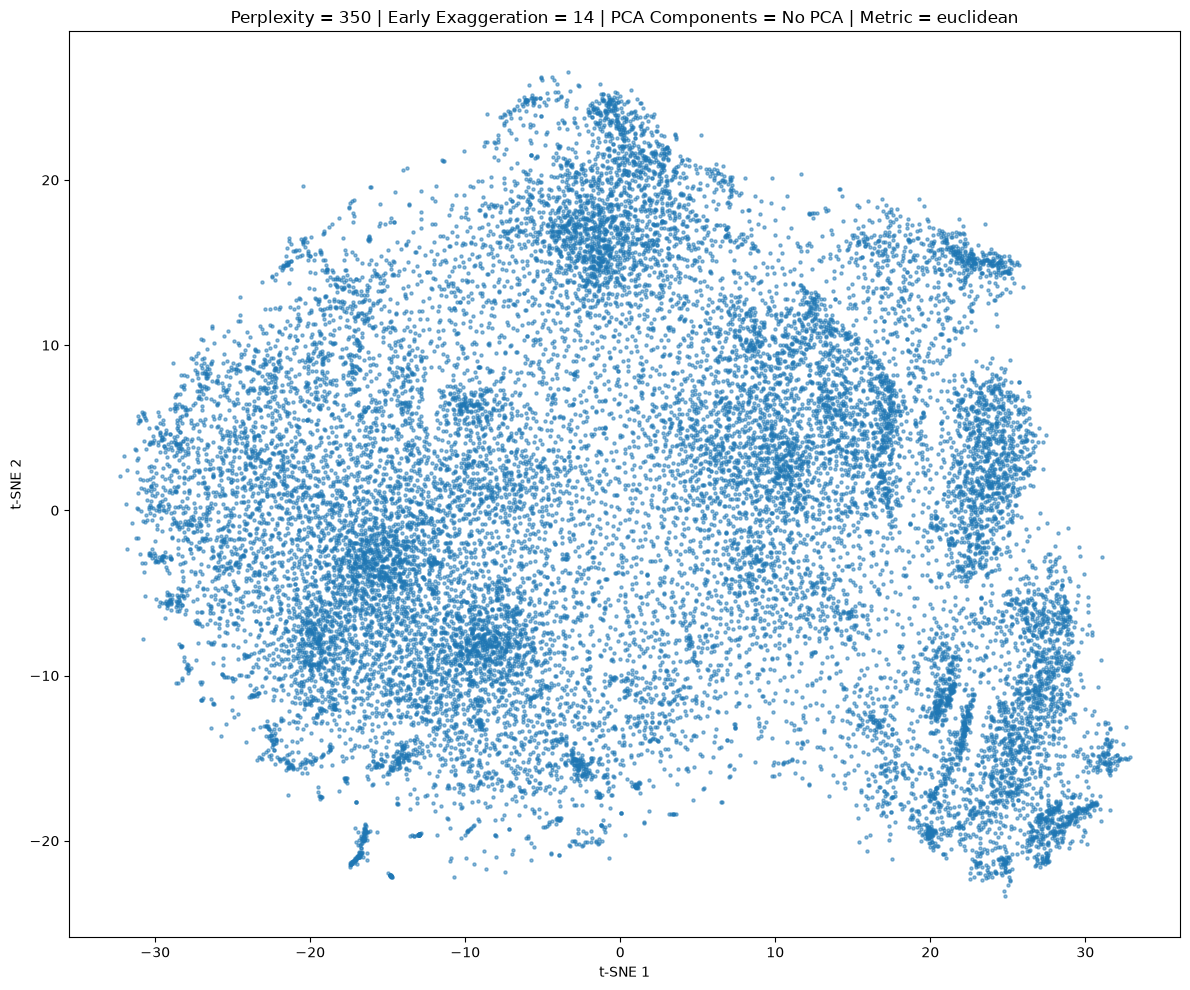

In [81]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"Perplexity = {PERPLEXITY} | Early Exaggeration = 14 | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()